## Make datasets and plot them


In [250]:
#Import make_moons to make the dataset for classification
from sklearn.datasets import make_moons
import os, requests      #Helper functions for mapping the boundary later

if not os.path.exists("helper_functions.py"):
  r = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py")
  open("helper_functions.py", "wb").write(r.content)

from helper_functions import plot_decision_boundary

In [251]:
n_samples = 2000   #No of total samples to train and test on
manualSeed=42      #Seed for same generation, can be altered

X,y = make_moons(n_samples=n_samples,
                 noise=0.15,
                 random_state=manualSeed)

X.shape, y.shape  #Note that these values are in numpy

((2000, 2), (2000,))

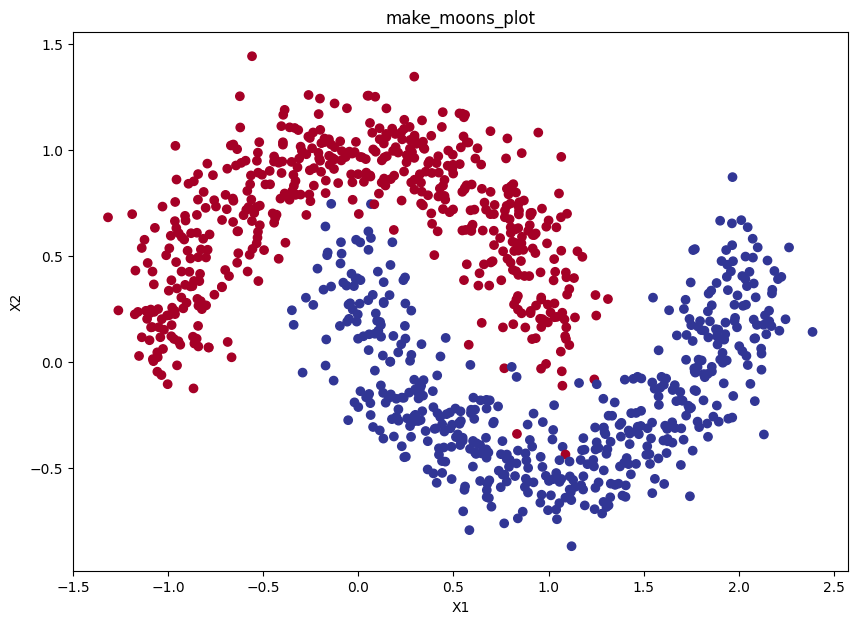

In [252]:
import matplotlib.pyplot as plt

#Plot half of the samples to get an idea of what we are dealing with
plt.figure(figsize=(10,7))

plt.scatter(X[:1000,0],
            X[:1000,1],
            c=y[:1000],
            cmap=plt.cm.RdYlBu)
plt.title("make_moons_plot")
plt.xlabel("X1")
plt.ylabel("X2")

plt.show()

In [253]:
from sklearn.model_selection import train_test_split    #Very good function to make training and test splits rather than slicing

#Set the device variable
device = "cuda" if torch.cuda.is_available() else "cpu"

#Convert to  tensors and bring all the tensors to the same device
X = torch.from_numpy(X).to(device)
y = torch.from_numpy(y).to(device)

#Split the dataset into training and testing. Here split: 50%
X_train,X_test,y_train,y_test = train_test_split(X,
                                                 y,
                                                 test_size=0.5,
                                                 random_state=manualSeed)

## Make the model class and a model instance

In [254]:
import torch
from torch import nn      #Most important imports

In [255]:
class MoonModel(nn.Module):
  def __init__(self, input_features=2, output_features=1, hidden_layer_1=8, hidden_layer_2=8):
    '''Creates a 4 layer neural network as per the given parameters.

    Args:
      input_features:  Number of inputs being taken into the neural network.
                       Here default: 2
      output_features: Number of  tensors being thrown  out as  output from
                       the given neural net.
      hidden_layer_1:  Number  of  neurons  in the first hidden  layer  for
                       more accuracy.
      hidden_layer_2:  Same as for hidden_layer_1.

    Returns:
      A tensor corresponding to the output of the weights it is trained on.
    '''
    super().__init__()
    self.perceptron = nn.Sequential(
        nn.Linear(in_features=input_features, out_features=hidden_layer_1), #Input Layer
        nn.ReLU(),
        nn.Linear(in_features=hidden_layer_1, out_features=hidden_layer_1), #First hidden Layer
        nn.ReLU(),
        nn.Linear(in_features=hidden_layer_1, out_features=hidden_layer_2),
        nn.ReLU(),
        nn.Linear(in_features=hidden_layer_2, out_features=hidden_layer_2), #Second hidden layer
        nn.ReLU(),
        nn.Linear(in_features=hidden_layer_2, out_features=output_features) #Final output layer
    )

  def forward(self,x:torch.Tensor) -> torch.Tensor:     #Forward pass function
    return self.perceptron(x)

In [256]:
#Creating an instance of a model with two hidden layers of 10 neurons each
model =  MoonModel(2, 1, 10, 10)
model

MoonModel(
  (perceptron): Sequential(
    (0): Linear(in_features=2, out_features=10, bias=True)
    (1): ReLU()
    (2): Linear(in_features=10, out_features=10, bias=True)
    (3): ReLU()
    (4): Linear(in_features=10, out_features=10, bias=True)
    (5): ReLU()
    (6): Linear(in_features=10, out_features=10, bias=True)
    (7): ReLU()
    (8): Linear(in_features=10, out_features=1, bias=True)
  )
)

### Setup Loss Fn, Accuracy Fn and an Optimizer

In [257]:
#Setup the Loss Fn, Accuracy Fn and Optimizer
learning_rate = 0.05     #Mild learning rate. Try lr= [0.03, 0.01, 0.1,...]

loss_fn = nn.BCEWithLogitsLoss()     #This one just worked out for me. Maybe I need to try more.
optimizer  = torch.optim.Adam(params=model.parameters(), lr=learning_rate)       #Same for the optimizer

#Setup the accuracy function
def accuracy(input, target):
  acc = torch.eq(input, target).sum().item()
  return (acc/len(target)) * 100

In [258]:
#Storage chamber for analysis
epoch_count = []
train_losses = []
train_accuracies = []
test_losses = []
test_accuracies = []

## Training and Evaluation Loop

In [259]:
#Set the number of training runs
epochs = 1000
#Manual seeds for pseudo natural generation
torch.manual_seed = manualSeed

for epoch in range(1,epochs+1):
  #Training Loops
  model.train()

  # Forward pass
  y_logits = model(X_train.type(torch.float)).squeeze(dim=1)
  y_predProbs = torch.sigmoid(y_logits)
  y_labels = torch.round(y_predProbs)

  #Gradient
  optimizer.zero_grad()

  #Loss and Accuracy Calculation
  loss = loss_fn(y_logits, y_train.type(torch.float))
  acc =  accuracy(y_labels, y_train)

  #Backpropagation
  loss.backward()

  #Gradient Descent
  optimizer.step()

  #Evaluation Loop
  model.eval()
  with torch.inference_mode():

    #Test forward
    y_test_logits = model(X_test.type(torch.float)).squeeze()
    y_test_labels = torch.round(torch.sigmoid(y_test_logits))

    #Test Loss and Accuracy Calculation
    test_loss = loss_fn(y_test_logits, y_test.type(torch.float))
    test_acc =  accuracy(y_test_labels, y_test)


  if epoch%20 == 0:
    print(f"Epoch:{epoch} | Loss:{loss:.5f} | Accuracy:{acc:.2f} | Loss:{test_loss:.5f} | Accuracy:{test_acc:.2f}")
    epoch_count.append(epoch)
    train_losses.append(loss.detach().numpy())
    train_accuracies.append(acc)
    test_losses.append(test_loss.detach().numpy())
    test_accuracies.append(test_acc)

Epoch:20 | Loss:0.17988 | Accuracy:92.50 | Loss:0.18095 | Accuracy:92.60
Epoch:40 | Loss:0.02850 | Accuracy:99.10 | Loss:0.02410 | Accuracy:99.00
Epoch:60 | Loss:0.02476 | Accuracy:99.40 | Loss:0.02461 | Accuracy:99.10
Epoch:80 | Loss:0.02209 | Accuracy:99.40 | Loss:0.02487 | Accuracy:99.20
Epoch:100 | Loss:0.02176 | Accuracy:99.20 | Loss:0.02526 | Accuracy:99.20
Epoch:120 | Loss:0.02157 | Accuracy:99.30 | Loss:0.02588 | Accuracy:99.20
Epoch:140 | Loss:0.02138 | Accuracy:99.30 | Loss:0.02628 | Accuracy:99.20
Epoch:160 | Loss:0.02121 | Accuracy:99.20 | Loss:0.02681 | Accuracy:99.20
Epoch:180 | Loss:0.02105 | Accuracy:99.20 | Loss:0.02733 | Accuracy:99.20
Epoch:200 | Loss:0.02092 | Accuracy:99.20 | Loss:0.02783 | Accuracy:99.20
Epoch:220 | Loss:0.02086 | Accuracy:99.20 | Loss:0.02745 | Accuracy:99.20
Epoch:240 | Loss:0.02076 | Accuracy:99.20 | Loss:0.02835 | Accuracy:99.20
Epoch:260 | Loss:0.02039 | Accuracy:99.20 | Loss:0.02916 | Accuracy:99.20
Epoch:280 | Loss:0.01995 | Accuracy:99.30 

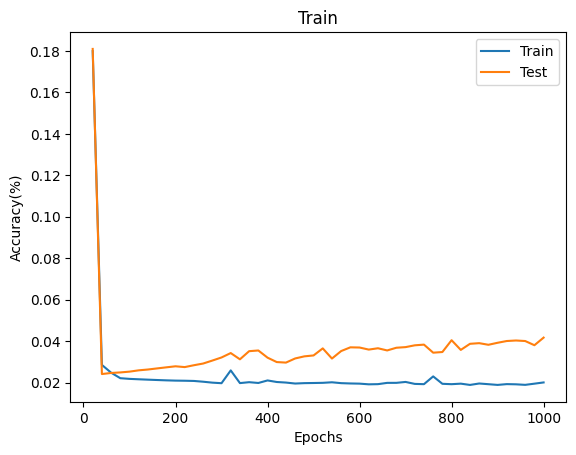

In [260]:
plt.title("Train")
plt.plot(epoch_count, train_losses, label="Train")
plt.plot(epoch_count, test_losses, label="Test")
plt.xlabel("Epochs")
plt.ylabel("Accuracy(%)")

plt.legend()
plt.show()

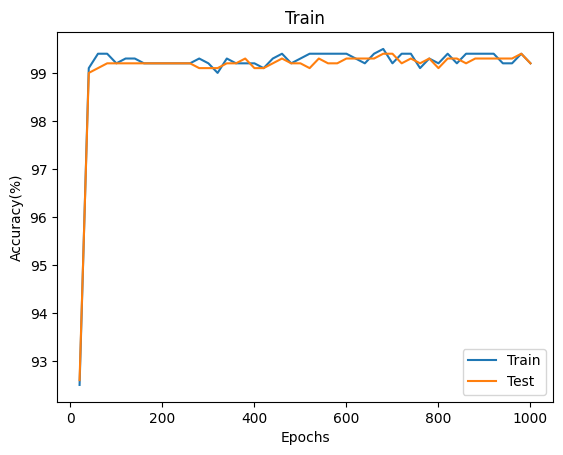

In [261]:
plt.title("Train")
plt.plot(epoch_count, train_accuracies, label="Train")
plt.plot(epoch_count, test_accuracies, label="Test")
plt.xlabel("Epochs")
plt.ylabel("Accuracy(%)")

plt.legend()
plt.show()

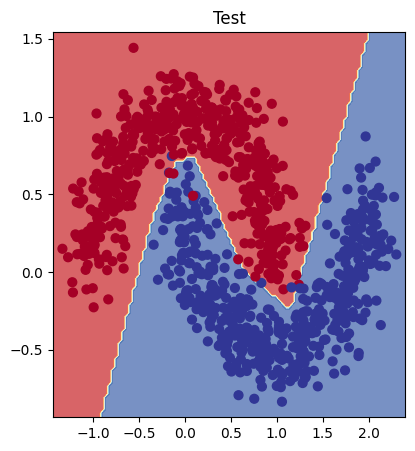

In [263]:
# Plot decision boundaries for training and test sets
plt.figure(figsize=(10,5))

plt.subplot(1, 2, 2)
plt.title("Test")
plot_decision_boundary(model, X_test, y_test)